
# پیش‌بینی PM10 با مدل‌های یادگیری ماشین کلاسیک در سه افق 1، 24 و 72 ساعت

این نوت‌بوک برای **مقایسه‌ی منصفانه با نوت‌بوک‌های RNN/LSTM/GRU** طراحی شده است.

## اصل طراحی مقایسه

در تمام مدل‌ها و تمام افق‌ها موارد زیر ثابت هستند:

- دیتاست: `Gucheng.csv`
- متغیر هدف: `PM10`
- نوع مسئله: Multivariate Time-Series Forecasting، بدون مدل‌سازی مکانی
- طول پنجره ورودی: `LOOKBACK = 24` ساعت
- همان 19 ویژگی مورد استفاده در مدل‌های عمیق
- همان مدیریت مقادیر گمشده
- همان کدگذاری چرخه‌ای زمان و جهت باد
- همان تقسیم زمانی `70% Train / 15% Validation / 15% Test`
- همان StandardScaler که فقط روی Train برازش می‌شود
- همان Persistence baseline
- همان معیارهای `MAE`, `RMSE`, `R²`, `sMAPE`
- همان ارزیابی Peak Pollution بر اساس صدک 90 مجموعه Test
- همان Seed برابر 42

## مدل‌های کلاسیک

1. Ridge Regression
2. Support Vector Regression (RBF-SVR)
3. Random Forest
4. XGBoost

## تنها تفاوت ساختاری ضروری با شبکه‌های بازگشتی

ورودی شبکه‌های RNN/LSTM/GRU به شکل زیر بود:

\[
(\text{samples}, 24, 19)
\]

مدل‌های کلاسیک ورودی سه‌بعدی دریافت نمی‌کنند. بنابراین **بدون حذف یا افزودن هیچ اطلاعاتی**، هر پنجره فقط Flatten می‌شود:

\[
24 \times 19 = 456
\]

در نتیجه ورودی مدل‌های کلاسیک به شکل زیر است:

\[
(\text{samples}, 456)
\]

موقعیت زمانی هر ویژگی در بردار حفظ می‌شود؛ بنابراین برای مثال `PM10` در ساعت `t-23` یک ستون مجزا از `PM10` در ساعت `t` دارد.

## سه آزمایش

\[
(X_{t-23},\ldots,X_t) \rightarrow PM10_{t+1}
\]

\[
(X_{t-23},\ldots,X_t) \rightarrow PM10_{t+24}
\]

\[
(X_{t-23},\ldots,X_t) \rightarrow PM10_{t+72}
\]

برای تضمین مقایسه‌ی کنترل‌شده، **هایپرپارامترهای مدل‌های کلاسیک نیز بین سه افق ثابت نگه داشته می‌شوند**.



## 1. نصب کتابخانه‌ها

اگر محیط شما `xgboost` یا سایر کتابخانه‌ها را ندارد، خط زیر را یک بار اجرا کنید.


In [1]:
# Optional installation (uncomment if needed)
!pip install -q xgboost scikit-learn pandas matplotlib joblib

## 2. کتابخانه‌ها و تنظیمات بازتولیدپذیری

In [2]:
import os
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---------------------------
# Experiment configuration
# ---------------------------
DATA_PATH = Path("Gucheng.csv")
TARGET = "PM10"

LOOKBACK = 24
HORIZONS = [1, 24, 72]

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9

print("Data path:", DATA_PATH.resolve())
print("LOOKBACK:", LOOKBACK)
print("HORIZONS:", HORIZONS)

Data path: /content/Gucheng.csv
LOOKBACK: 24
HORIZONS: [1, 24, 72]



## 3. هایپرپارامترهای ثابت مدل‌ها

برای اینکه مقایسه بین افق‌های 1، 24 و 72 ساعت منصفانه باشد، تنظیمات هیچ مدل در طول این سه آزمایش تغییر نمی‌کند.

در این مرحله عمداً از Hyperparameter Tuning استفاده نمی‌شود؛ زیرا هدف، ساخت یک **benchmark کنترل‌شده** و قابل مقایسه با RNN/LSTM/GRU فعلی است. اگر در مرحله بعد تصمیم به tuning گرفته شود، باید برای همه خانواده‌های مدل با بودجه اعتبارسنجی مشابه انجام شود.


In [3]:
CLASSICAL_MODEL_CONFIG = {
    "Ridge": {
        "alpha": 1.0
    },
    "SVR": {
        "kernel": "rbf",
        "C": 10.0,
        "epsilon": 0.1,
        "gamma": "scale",
        "cache_size": 2000
    },
    "RandomForest": {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": 1.0,
        "n_jobs": -1,
        "random_state": SEED
    },
    "XGBoost": {
        "n_estimators": 500,
        "max_depth": 6,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "objective": "reg:squarederror",
        "tree_method": "hist",
        "n_jobs": -1,
        "random_state": SEED,
        "verbosity": 0
    }
}

display(pd.DataFrame(CLASSICAL_MODEL_CONFIG).T)

,alpha,kernel,C,epsilon,gamma,cache_size,n_estimators,max_depth,min_samples_leaf,max_features,n_jobs,random_state,learning_rate,subsample,colsample_bytree,objective,tree_method,verbosity
Ridge,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SVR,NaN,rbf,10.0,0.1,scale,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RandomForest,NaN,NaN,NaN,NaN,NaN,NaN,300.0,NaN,1.0,1.0,-1.0,42.0,NaN,NaN,NaN,NaN,NaN,NaN
XGBoost,NaN,NaN,NaN,NaN,NaN,NaN,500,6,NaN,NaN,-1,42,0.05,0.8,0.8,reg:squarederror,hist,0


In [4]:
from google.colab import files
uploaded = files.upload()

Saving Gucheng.csv to Gucheng.csv



## 4. بارگذاری داده و ساخت محور زمانی

این بخش عمداً مطابق pipeline مدل‌های عمیق نگه داشته شده است.


In [5]:
df_raw = pd.read_csv('Gucheng.csv')

required_columns = [
    "year", "month", "day", "hour",
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "wd", "WSPM"
]

missing_required = [c for c in required_columns if c not in df_raw.columns]
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

df = df_raw.copy()
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.sort_values("datetime").reset_index(drop=True)

print("Shape:", df.shape)
print("Time range:", df["datetime"].min(), "to", df["datetime"].max())
display(df.head())

Shape: (35064, 19)
Time range: 2013-03-01 00:00:00 to 2017-02-28 23:00:00


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,6.0,18.0,5.0,NaN,800.0,88.0,0.1,1021.1,-18.6,0.0,NW,4.4,Gucheng,2013-03-01 00:00:00
1,2,2013,3,1,1,6.0,15.0,5.0,NaN,800.0,88.0,-0.3,1021.5,-19.0,0.0,NW,4.0,Gucheng,2013-03-01 01:00:00
2,3,2013,3,1,2,5.0,18.0,NaN,NaN,700.0,52.0,-0.7,1021.5,-19.8,0.0,WNW,4.6,Gucheng,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,20.0,6.0,NaN,NaN,NaN,-1.0,1022.7,-21.2,0.0,W,2.8,Gucheng,2013-03-01 03:00:00
4,5,2013,3,1,4,5.0,17.0,5.0,NaN,600.0,73.0,-1.3,1023.0,-21.4,0.0,WNW,3.6,Gucheng,2013-03-01 04:00:00


## 5. کنترل کیفیت اولیه سری زمانی

In [6]:
duplicate_times = df["datetime"].duplicated().sum()
time_diffs = df["datetime"].diff().dropna()
irregular_steps = (time_diffs != pd.Timedelta(hours=1)).sum()

print("Duplicate timestamps:", duplicate_times)
print("Irregular (non-hourly) time steps:", irregular_steps)

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (100 * df.isna().mean()).round(3)
}).sort_values("missing_percent", ascending=False)

display(missing_summary[missing_summary["missing_count"] > 0])

if duplicate_times > 0:
    raise ValueError("Duplicate timestamps detected. Resolve them before modeling.")
if irregular_steps > 0:
    print("WARNING: The time series is not perfectly hourly.")

Duplicate timestamps: 0
Irregular (non-hourly) time steps: 0


,missing_count,missing_percent
CO,1401,3.996
O3,729,2.079
NO2,668,1.905
PM2.5,646,1.842
SO2,507,1.446
PM10,381,1.087
wd,159,0.453
DEWP,51,0.145
TEMP,51,0.145
PRES,50,0.143


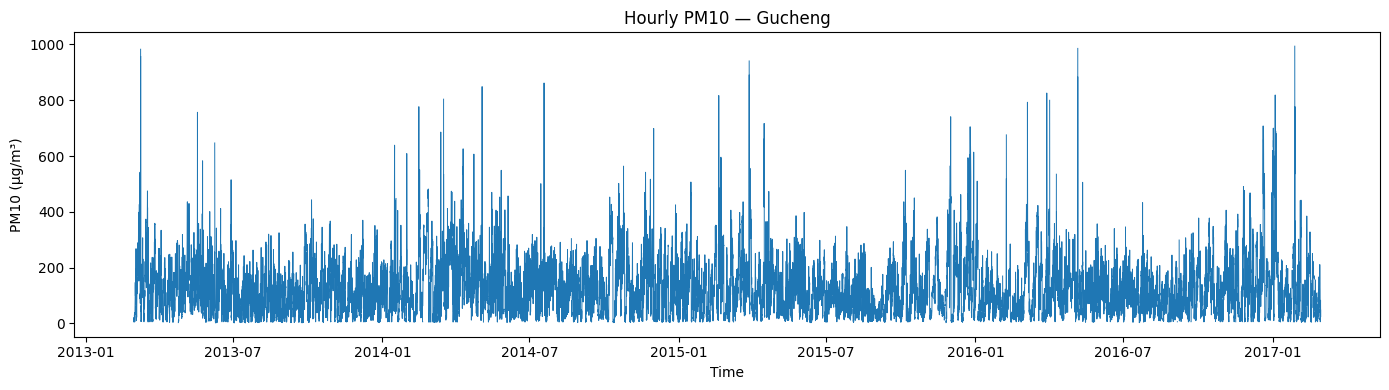

In [7]:
plt.figure(figsize=(14, 4))
plt.plot(df["datetime"], df["PM10"], linewidth=0.7)
plt.title("Hourly PM10 — Gucheng")
plt.xlabel("Time")
plt.ylabel("PM10 (µg/m³)")
plt.tight_layout()
plt.show()


## 6. تعیین مرزهای Train / Validation / Test

دقیقاً مانند مدل‌های عمیق، تقسیم داده **Chronological** است و قبل از imputation آماری و scaling تعیین می‌شود.


In [8]:
n = len(df)
train_end = int(n * TRAIN_RATIO)
val_end = int(n * (TRAIN_RATIO + VAL_RATIO))

print("Total rows:", n)
print("Train rows:", train_end)
print("Validation rows:", val_end - train_end)
print("Test rows:", n - val_end)

print("\nTrain:", df.loc[0, "datetime"], "→", df.loc[train_end - 1, "datetime"])
print("Validation:", df.loc[train_end, "datetime"], "→", df.loc[val_end - 1, "datetime"])
print("Test:", df.loc[val_end, "datetime"], "→", df.loc[n - 1, "datetime"])

Total rows: 35064
Train rows: 24544
Validation rows: 5260
Test rows: 5260

Train: 2013-03-01 00:00:00 → 2015-12-18 15:00:00
Validation: 2015-12-18 16:00:00 → 2016-07-24 19:00:00
Test: 2016-07-24 20:00:00 → 2017-02-28 23:00:00



## 7. مدیریت مقادیر گمشده بدون نشت اطلاعات

همان روش مدل‌های عمیق استفاده می‌شود:

1. `Forward Fill` برای استفاده فقط از گذشته
2. برای مقادیر باقی‌مانده در ابتدای سری، median متغیرهای عددی فقط از Train
3. برای جهت باد، mode فقط از Train

هیچ interpolation دوطرفه‌ای که آینده را ببیند استفاده نمی‌شود.


In [9]:
numeric_measure_cols = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

train_medians = df.loc[:train_end - 1, numeric_measure_cols].median()
train_wd_mode = df.loc[:train_end - 1, "wd"].mode(dropna=True)
train_wd_mode = train_wd_mode.iloc[0] if len(train_wd_mode) else "N"

df[numeric_measure_cols] = df[numeric_measure_cols].ffill()
df["wd"] = df["wd"].ffill()

df[numeric_measure_cols] = df[numeric_measure_cols].fillna(train_medians)
df["wd"] = df["wd"].fillna(train_wd_mode)

print(
    "Remaining missing values in modeling columns:",
    int(df[numeric_measure_cols + ["wd"]].isna().sum().sum())
)

Remaining missing values in modeling columns: 0



## 8. مهندسی ویژگی‌های زمانی و جهت باد

این بخش بدون تغییر نسبت به نوت‌بوک‌های RNN/LSTM/GRU اجرا می‌شود.

ویژگی‌های چرخه‌ای:

- `hour_sin`, `hour_cos`
- `month_sin`, `month_cos`
- `dow_sin`, `dow_cos`
- `wd_sin`, `wd_cos`


In [10]:
df["dow"] = df["datetime"].dt.dayofweek

df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["month_sin"] = np.sin(2 * np.pi * (df["month"] - 1) / 12)
df["month_cos"] = np.cos(2 * np.pi * (df["month"] - 1) / 12)

df["dow_sin"] = np.sin(2 * np.pi * df["dow"] / 7)
df["dow_cos"] = np.cos(2 * np.pi * df["dow"] / 7)

wind_degrees = {
    "N": 0.0, "NNE": 22.5, "NE": 45.0, "ENE": 67.5,
    "E": 90.0, "ESE": 112.5, "SE": 135.0, "SSE": 157.5,
    "S": 180.0, "SSW": 202.5, "SW": 225.0, "WSW": 247.5,
    "W": 270.0, "WNW": 292.5, "NW": 315.0, "NNW": 337.5
}

unknown_wd = sorted(set(df["wd"].dropna().unique()) - set(wind_degrees))
if unknown_wd:
    raise ValueError(f"Unknown wind-direction categories: {unknown_wd}")

wd_rad = np.deg2rad(df["wd"].map(wind_degrees).astype(float))
df["wd_sin"] = np.sin(wd_rad)
df["wd_cos"] = np.cos(wd_rad)

display(df[[
    "datetime", "hour_sin", "hour_cos",
    "month_sin", "month_cos", "dow_sin", "dow_cos",
    "wd", "wd_sin", "wd_cos"
]].head())

,datetime,hour_sin,hour_cos,month_sin,month_cos,dow_sin,dow_cos,wd,wd_sin,wd_cos
0,2013-03-01 00:00:00,0.000000,1.000000,0.866025,0.5,-0.433884,-0.900969,NW,-0.707107,7.071068e-01
1,2013-03-01 01:00:00,0.258819,0.965926,0.866025,0.5,-0.433884,-0.900969,NW,-0.707107,7.071068e-01
2,2013-03-01 02:00:00,0.500000,0.866025,0.866025,0.5,-0.433884,-0.900969,WNW,-0.923880,3.826834e-01
3,2013-03-01 03:00:00,0.707107,0.707107,0.866025,0.5,-0.433884,-0.900969,W,-1.000000,-1.836970e-16
4,2013-03-01 04:00:00,0.866025,0.500000,0.866025,0.5,-0.433884,-0.900969,WNW,-0.923880,3.826834e-01


## 9. مجموعه 19 ویژگی ورودی

In [11]:
FEATURES = [
    # Pollutants
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    # Meteorology
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM",
    # Cyclical calendar features
    "hour_sin", "hour_cos",
    "month_sin", "month_cos",
    "dow_sin", "dow_cos",
    # Wind direction
    "wd_sin", "wd_cos"
]

print("Number of input features:", len(FEATURES))
print(FEATURES)

assert len(FEATURES) == 19

display(df[FEATURES + [TARGET]].describe().T)

Number of input features: 19
['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dow_sin', 'dow_cos', 'wd_sin', 'wd_cos']


,count,mean,std,min,25%,50%,75%,max
PM2.5,35064.0,8.434520e+01,83.228885,2.000000,24.000000,6.000000e+01,116.000000,770.000000
PM10,35064.0,1.193290e+02,97.650791,2.000000,45.000000,1.000000e+02,167.000000,994.000000
SO2,35064.0,1.602008e+01,27.031552,0.285600,2.000000,7.000000e+00,20.000000,500.000000
NO2,35064.0,5.582096e+01,36.525063,2.000000,26.000000,5.000000e+01,79.000000,276.000000
CO,35064.0,1.352702e+03,1236.264470,100.000000,600.000000,9.000000e+02,1700.000000,10000.000000
O3,35064.0,5.870256e+01,58.243262,0.214200,10.000000,4.500000e+01,84.000000,450.000000
TEMP,35064.0,1.385569e+01,11.295553,-15.600000,3.600000,1.480000e+01,23.500000,41.600000
PRES,35064.0,1.008836e+03,10.104802,984.000000,1000.500000,1.008500e+03,1017.000000,1038.100000
DEWP,35064.0,2.600456e+00,13.789758,-34.600000,-9.000000,3.000000e+00,15.300000,27.400000
RAIN,35064.0,6.437372e-02,0.838142,0.000000,0.000000,0.000000e+00,0.000000,41.900000



## 10. Scaling فقط بر اساس Train

برای حفظ بیشترین سازگاری با مدل‌های عمیق:

- `feature_scaler` روی 19 ویژگی Train برازش می‌شود.
- `target_scaler` روی PM10 بخش Train برازش می‌شود.
- Validation و Test فقط Transform می‌شوند.

هر چهار مدل کلاسیک همان ورودی استانداردشده را دریافت می‌کنند.  
برای مدل‌های درختی scaling الزامی نیست، اما استفاده از همان داده‌ی ورودی مدل‌های عمیق، مقایسه را کنترل‌شده‌تر می‌کند.


In [12]:
feature_scaler = StandardScaler()
target_scaler = StandardScaler()

feature_scaler.fit(df.loc[:train_end - 1, FEATURES])
target_scaler.fit(df.loc[:train_end - 1, [TARGET]])

X_all_scaled = feature_scaler.transform(df[FEATURES]).astype(np.float32)
y_all_scaled = target_scaler.transform(df[[TARGET]]).astype(np.float32).reshape(-1)

print("Scaled feature matrix:", X_all_scaled.shape)
print("Scaled target vector:", y_all_scaled.shape)

Scaled feature matrix: (35064, 19)
Scaled target vector: (35064,)



## 11. ساخت Sliding Window و Flatten برای مدل‌های کلاسیک

تابع زیر دقیقاً همان منطق زمانی مورد استفاده در مدل‌های عمیق را حفظ می‌کند.

برای هر horizon:

\[
X = [X_{t-23},\ldots,X_t]
\]

و هدف:

\[
y = PM10_{t+h}
\]

سپس تنها برای سازگاری با الگوریتم‌های کلاسیک:

\[
(24,19)\rightarrow456
\]

انجام می‌شود.


In [13]:
def create_forecasting_windows(X, y, datetimes, lookback=24, horizon=1):
    X_seq, y_seq, target_indices, target_times = [], [], [], []

    first_target = lookback + horizon - 1

    for target_idx in range(first_target, len(X)):
        input_end = target_idx - horizon + 1  # exclusive
        input_start = input_end - lookback

        X_seq.append(X[input_start:input_end])
        y_seq.append(y[target_idx])
        target_indices.append(target_idx)
        target_times.append(datetimes.iloc[target_idx])

    return (
        np.asarray(X_seq, dtype=np.float32),
        np.asarray(y_seq, dtype=np.float32),
        np.asarray(target_indices, dtype=np.int64),
        pd.DatetimeIndex(target_times)
    )


def prepare_horizon_data(horizon):
    X_seq, y_seq, target_indices, target_times = create_forecasting_windows(
        X_all_scaled,
        y_all_scaled,
        df["datetime"],
        lookback=LOOKBACK,
        horizon=horizon
    )

    train_mask = target_indices < train_end
    val_mask = (target_indices >= train_end) & (target_indices < val_end)
    test_mask = target_indices >= val_end

    X_train_3d = X_seq[train_mask]
    X_val_3d = X_seq[val_mask]
    X_test_3d = X_seq[test_mask]

    y_train = y_seq[train_mask]
    y_val = y_seq[val_mask]
    y_test = y_seq[test_mask]

    time_train = target_times[train_mask]
    time_val = target_times[val_mask]
    time_test = target_times[test_mask]

    # Classical models receive exactly the same information,
    # only reshaped from (samples, 24, 19) to (samples, 456).
    X_train = X_train_3d.reshape(len(X_train_3d), -1)
    X_val = X_val_3d.reshape(len(X_val_3d), -1)
    X_test = X_test_3d.reshape(len(X_test_3d), -1)

    assert X_train.shape[1] == LOOKBACK * len(FEATURES)
    assert X_val.shape[1] == LOOKBACK * len(FEATURES)
    assert X_test.shape[1] == LOOKBACK * len(FEATURES)

    return {
        "X_train_3d": X_train_3d,
        "X_val_3d": X_val_3d,
        "X_test_3d": X_test_3d,
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test,
        "target_indices": target_indices,
        "test_target_indices": target_indices[test_mask],
        "time_train": time_train,
        "time_val": time_val,
        "time_test": time_test
    }

### کنترل ابعاد داده برای هر سه افق

In [14]:
for h in HORIZONS:
    d = prepare_horizon_data(h)
    print(f"\nHorizon = {h}h")
    print("Deep-learning equivalent input:", d["X_train_3d"].shape)
    print("Classical flattened input:      ", d["X_train"].shape)
    print("Validation:                     ", d["X_val"].shape)
    print("Test:                           ", d["X_test"].shape)


Horizon = 1h
Deep-learning equivalent input: (24520, 24, 19)
Classical flattened input:       (24520, 456)
Validation:                      (5260, 456)
Test:                            (5260, 456)

Horizon = 24h
Deep-learning equivalent input: (24497, 24, 19)
Classical flattened input:       (24497, 456)
Validation:                      (5260, 456)
Test:                            (5260, 456)

Horizon = 72h
Deep-learning equivalent input: (24449, 24, 19)
Classical flattened input:       (24449, 456)
Validation:                      (5260, 456)
Test:                            (5260, 456)



## 12. Persistence Baseline

در هر افق، همان منطق Persistence مدل‌های عمیق حفظ می‌شود:

\[
\hat{PM10}_{t+h}=PM10_t
\]

بنابراین:

- 1h: مقدار فعلی برای یک ساعت بعد
- 24h: مقدار فعلی برای 24 ساعت بعد
- 72h: مقدار فعلی برای 72 ساعت بعد


In [15]:
pm10_feature_idx = FEATURES.index("PM10")
pm10_mean_feature = feature_scaler.mean_[pm10_feature_idx]
pm10_scale_feature = feature_scaler.scale_[pm10_feature_idx]


def persistence_from_windows(X_test_3d):
    last_scaled_pm10 = X_test_3d[:, -1, pm10_feature_idx]
    return last_scaled_pm10 * pm10_scale_feature + pm10_mean_feature

## 13. توابع ارزیابی مشترک

In [16]:
def smape(y_true, y_pred, eps=1e-8):
    denominator = np.abs(y_true) + np.abs(y_pred)
    return 100.0 * np.mean(
        2.0 * np.abs(y_pred - y_true) / np.maximum(denominator, eps)
    )


def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "sMAPE_percent": smape(y_true, y_pred)
    }

## 14. ساخت مدل‌های کلاسیک

In [17]:
def build_classical_models():
    # A fresh model is created for every horizon.
    return {
        "Ridge": Ridge(
            alpha=CLASSICAL_MODEL_CONFIG["Ridge"]["alpha"]
        ),

        "SVR": SVR(
            kernel=CLASSICAL_MODEL_CONFIG["SVR"]["kernel"],
            C=CLASSICAL_MODEL_CONFIG["SVR"]["C"],
            epsilon=CLASSICAL_MODEL_CONFIG["SVR"]["epsilon"],
            gamma=CLASSICAL_MODEL_CONFIG["SVR"]["gamma"],
            cache_size=CLASSICAL_MODEL_CONFIG["SVR"]["cache_size"]
        ),

        "RandomForest": RandomForestRegressor(
            n_estimators=CLASSICAL_MODEL_CONFIG["RandomForest"]["n_estimators"],
            max_depth=CLASSICAL_MODEL_CONFIG["RandomForest"]["max_depth"],
            min_samples_leaf=CLASSICAL_MODEL_CONFIG["RandomForest"]["min_samples_leaf"],
            max_features=CLASSICAL_MODEL_CONFIG["RandomForest"]["max_features"],
            n_jobs=CLASSICAL_MODEL_CONFIG["RandomForest"]["n_jobs"],
            random_state=CLASSICAL_MODEL_CONFIG["RandomForest"]["random_state"]
        ),

        "XGBoost": XGBRegressor(
            n_estimators=CLASSICAL_MODEL_CONFIG["XGBoost"]["n_estimators"],
            max_depth=CLASSICAL_MODEL_CONFIG["XGBoost"]["max_depth"],
            learning_rate=CLASSICAL_MODEL_CONFIG["XGBoost"]["learning_rate"],
            subsample=CLASSICAL_MODEL_CONFIG["XGBoost"]["subsample"],
            colsample_bytree=CLASSICAL_MODEL_CONFIG["XGBoost"]["colsample_bytree"],
            objective=CLASSICAL_MODEL_CONFIG["XGBoost"]["objective"],
            tree_method=CLASSICAL_MODEL_CONFIG["XGBoost"]["tree_method"],
            n_jobs=CLASSICAL_MODEL_CONFIG["XGBoost"]["n_jobs"],
            random_state=CLASSICAL_MODEL_CONFIG["XGBoost"]["random_state"],
            verbosity=CLASSICAL_MODEL_CONFIG["XGBoost"]["verbosity"]
        )
    }


display(pd.DataFrame({
    "Model": list(build_classical_models().keys()),
    "Role": [
        "Linear regularized baseline",
        "Kernel-based nonlinear regression",
        "Bagging / ensemble tree model",
        "Gradient boosting tree model"
    ]
}))

,Model,Role
0,Ridge,Linear regularized baseline
1,SVR,Kernel-based nonlinear regression
2,RandomForest,Bagging / ensemble tree model
3,XGBoost,Gradient boosting tree model



## 15. تابع اجرای یک آزمایش کامل

برای هر horizon همین تابع واحد اجرا می‌شود.  
این موضوع اهمیت روش‌شناختی دارد؛ زیرا تضمین می‌کند هیچ تفاوت پنهانی میان کد 1h، 24h و 72h وجود ندارد.


In [18]:
OUTPUT_DIR = Path("outputs_gucheng_classical_all_horizons")
OUTPUT_DIR.mkdir(exist_ok=True)

all_experiments = {}


def run_classical_experiment(horizon):
    print("=" * 90)
    print(f"FORECAST HORIZON = {horizon} HOURS")
    print("=" * 90)

    data = prepare_horizon_data(horizon)

    X_train = data["X_train"]
    X_val = data["X_val"]
    X_test = data["X_test"]

    y_train = data["y_train"]
    y_val = data["y_val"]
    y_test = data["y_test"]

    y_test_real = target_scaler.inverse_transform(
        y_test.reshape(-1, 1)
    ).ravel()

    # Same Persistence baseline as the DL notebooks
    persistence_test = persistence_from_windows(data["X_test_3d"])

    metric_rows = []
    predictions_real = {}
    fitted_models = {}
    training_times = {}

    baseline_metrics = regression_metrics(y_test_real, persistence_test)
    metric_rows.append({
        "Horizon_hours": horizon,
        "Model": "Persistence",
        **baseline_metrics,
        "Training_seconds": 0.0
    })
    predictions_real["Persistence"] = persistence_test

    models = build_classical_models()

    for name, model in models.items():
        print(f"\nTraining {name} for {horizon}h horizon ...")

        start = time.perf_counter()

        # IMPORTANT:
        # Training uses ONLY the chronological Train partition.
        # Validation and Test are not used for fitting or tuning.
        model.fit(X_train, y_train)

        elapsed = time.perf_counter() - start
        training_times[name] = elapsed
        fitted_models[name] = model

        pred_scaled = np.asarray(model.predict(X_test)).reshape(-1, 1)
        pred_real = target_scaler.inverse_transform(pred_scaled).ravel()

        # No clipping: same evaluation philosophy as DL notebooks.
        predictions_real[name] = pred_real

        m = regression_metrics(y_test_real, pred_real)

        metric_rows.append({
            "Horizon_hours": horizon,
            "Model": name,
            **m,
            "Training_seconds": elapsed
        })

        print(
            f"{name}: MAE={m['MAE']:.3f} | "
            f"RMSE={m['RMSE']:.3f} | "
            f"R2={m['R2']:.4f} | "
            f"sMAPE={m['sMAPE_percent']:.3f}% | "
            f"time={elapsed:.1f}s"
        )

    comparison = (
        pd.DataFrame(metric_rows)
        .sort_values("RMSE")
        .reset_index(drop=True)
    )

    print("\nTEST RESULTS")
    display(comparison.round({
        "MAE": 3,
        "RMSE": 3,
        "R2": 4,
        "sMAPE_percent": 3,
        "Training_seconds": 1
    }))

    # Predictions table
    results = pd.DataFrame({
        "datetime": data["time_test"],
        "actual_PM10": y_test_real,
        **predictions_real
    })

    # Peak pollution evaluation: same definition as DL notebooks
    high_threshold = np.quantile(y_test_real, 0.90)
    high_mask = y_test_real >= high_threshold

    peak_rows = []
    for name, pred in predictions_real.items():
        m = regression_metrics(y_test_real[high_mask], pred[high_mask])
        peak_rows.append({
            "Horizon_hours": horizon,
            "Model": name,
            "Peak_threshold_PM10": high_threshold,
            "Peak_samples": int(high_mask.sum()),
            **m
        })

    peak_comparison = (
        pd.DataFrame(peak_rows)
        .sort_values("RMSE")
        .reset_index(drop=True)
    )

    print("\nPEAK-POLLUTION RESULTS (top 10% of actual test PM10)")
    display(peak_comparison.round(3))

    # Best classical model excludes Persistence
    best_classical_name = (
        comparison[comparison["Model"] != "Persistence"]
        .sort_values("RMSE")
        .iloc[0]["Model"]
    )

    print("\nBest classical model by Test RMSE:", best_classical_name)

    # Forecast plot
    N_PLOT = min(500, len(y_test_real))
    sl = slice(-N_PLOT, None)

    plt.figure(figsize=(15, 5))
    plt.plot(
        data["time_test"][sl],
        y_test_real[sl],
        label="Actual",
        linewidth=1.7
    )
    plt.plot(
        data["time_test"][sl],
        persistence_test[sl],
        label="Persistence",
        alpha=0.75
    )

    for name in ["Ridge", "SVR", "RandomForest", "XGBoost"]:
        plt.plot(
            data["time_test"][sl],
            predictions_real[name][sl],
            label=name,
            alpha=0.82
        )

    plt.title(f"PM10 Forecasts — Horizon {horizon}h — Last {N_PLOT} Test Samples")
    plt.xlabel("Target time")
    plt.ylabel("PM10 (µg/m³)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Residual analysis for best classical model
    best_pred = predictions_real[best_classical_name]
    residuals = y_test_real - best_pred

    plt.figure(figsize=(10, 4))
    plt.hist(residuals, bins=60)
    plt.title(f"{best_classical_name} — {horizon}h Test Residual Distribution")
    plt.xlabel("Residual = Actual - Prediction (µg/m³)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 4))
    plt.scatter(best_pred, residuals, s=8, alpha=0.35)
    plt.axhline(0, linewidth=1)
    plt.title(f"{best_classical_name} — {horizon}h Residuals vs Predicted")
    plt.xlabel("Predicted PM10 (µg/m³)")
    plt.ylabel("Residual (µg/m³)")
    plt.tight_layout()
    plt.show()

    # Save horizon-specific artifacts
    horizon_dir = OUTPUT_DIR / f"horizon_{horizon}h"
    horizon_dir.mkdir(exist_ok=True)

    comparison.to_csv(horizon_dir / "test_metrics.csv", index=False)
    peak_comparison.to_csv(horizon_dir / "peak_test_metrics.csv", index=False)
    results.to_csv(horizon_dir / "test_predictions.csv", index=False)

    for name, model in fitted_models.items():
        joblib.dump(model, horizon_dir / f"{name.lower()}_model.joblib")

    experiment = {
        "horizon": horizon,
        "data": data,
        "y_test_real": y_test_real,
        "predictions_real": predictions_real,
        "comparison": comparison,
        "peak_comparison": peak_comparison,
        "results": results,
        "best_classical_name": best_classical_name,
        "fitted_models": fitted_models,
        "training_times": training_times
    }

    all_experiments[horizon] = experiment

    return experiment


# آزمایش اول: پیش‌بینی یک ساعت آینده

\[
(X_{t-23},\ldots,X_t)\rightarrow PM10_{t+1}
\]

تمام تنظیمات همان pipeline مشترک هستند و فقط `horizon=1` است.


FORECAST HORIZON = 1 HOURS

Training Ridge for 1h horizon ...
Ridge: MAE=21.355 | RMSE=34.571 | R2=0.9013 | sMAPE=33.604% | time=0.2s

Training SVR for 1h horizon ...
SVR: MAE=32.732 | RMSE=54.879 | R2=0.7512 | sMAPE=41.364% | time=226.0s

Training RandomForest for 1h horizon ...
RandomForest: MAE=22.283 | RMSE=36.819 | R2=0.8880 | sMAPE=27.573% | time=1771.5s

Training XGBoost for 1h horizon ...
XGBoost: MAE=22.695 | RMSE=38.148 | R2=0.8798 | sMAPE=27.678% | time=35.0s

TEST RESULTS


,Horizon_hours,Model,MAE,RMSE,R2,sMAPE_percent,Training_seconds
0,1,Ridge,21.355,34.571,0.9013,33.604,0.2
1,1,Persistence,20.444,35.457,0.8961,24.241,0.0
2,1,RandomForest,22.283,36.819,0.8880,27.573,1771.5
3,1,XGBoost,22.695,38.148,0.8798,27.678,35.0
4,1,SVR,32.732,54.879,0.7512,41.364,226.0



PEAK-POLLUTION RESULTS (top 10% of actual test PM10)


,Horizon_hours,Model,Peak_threshold_PM10,Peak_samples,MAE,RMSE,R2,sMAPE_percent
0,1,Persistence,246.0,535,40.606,65.383,0.729,12.188
1,1,Ridge,246.0,535,43.087,66.236,0.722,13.005
2,1,RandomForest,246.0,535,45.253,69.306,0.695,13.325
3,1,XGBoost,246.0,535,51.767,78.783,0.606,15.126
4,1,SVR,246.0,535,95.156,137.788,-0.204,28.461



Best classical model by Test RMSE: Ridge


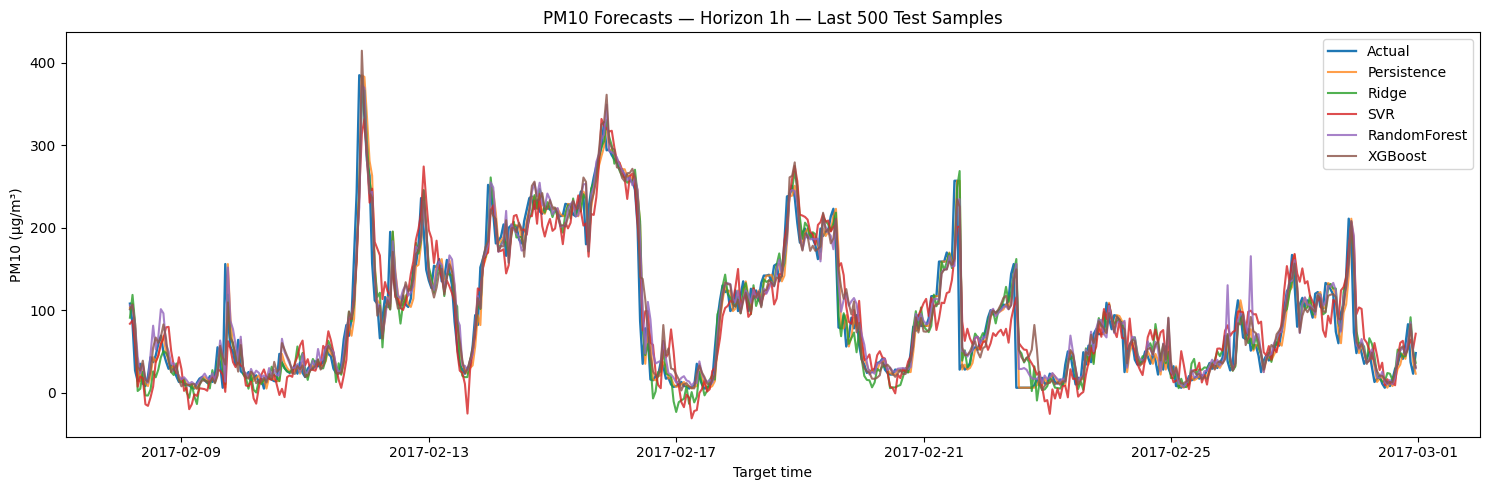

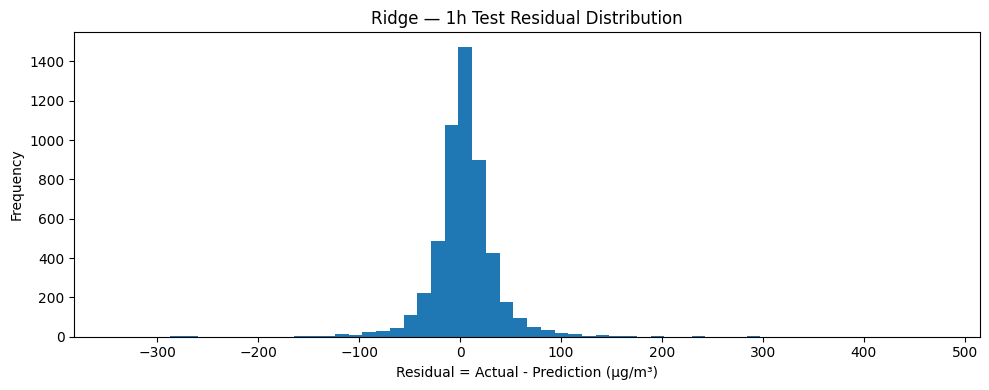

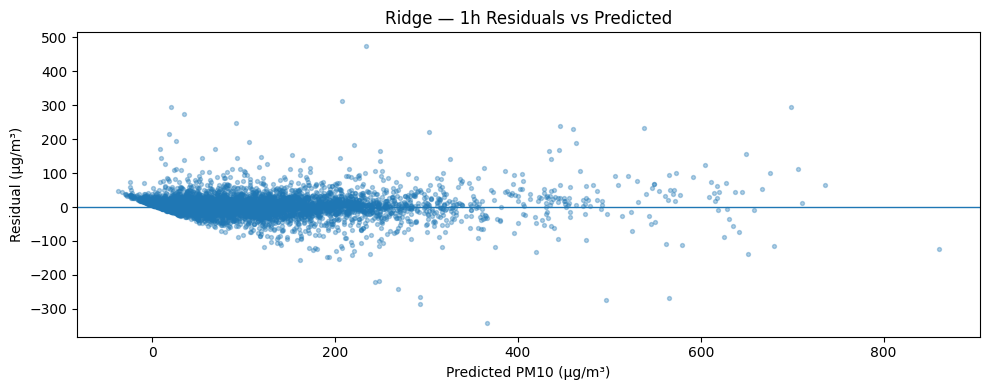

In [19]:
result_1h = run_classical_experiment(horizon=1)


# آزمایش دوم: پیش‌بینی 24 ساعت آینده

\[
(X_{t-23},\ldots,X_t)\rightarrow PM10_{t+24}
\]

هیچ تنظیم دیگری تغییر نمی‌کند.


FORECAST HORIZON = 24 HOURS

Training Ridge for 24h horizon ...
Ridge: MAE=70.083 | RMSE=101.371 | R2=0.1510 | sMAPE=68.828% | time=0.2s

Training SVR for 24h horizon ...
SVR: MAE=79.909 | RMSE=120.884 | R2=-0.2073 | sMAPE=77.645% | time=197.3s

Training RandomForest for 24h horizon ...
RandomForest: MAE=68.777 | RMSE=100.326 | R2=0.1684 | sMAPE=63.699% | time=1393.1s

Training XGBoost for 24h horizon ...
XGBoost: MAE=68.639 | RMSE=101.788 | R2=0.1440 | sMAPE=64.336% | time=35.2s

TEST RESULTS


,Horizon_hours,Model,MAE,RMSE,R2,sMAPE_percent,Training_seconds
0,24,RandomForest,68.777,100.326,0.1684,63.699,1393.1
1,24,Ridge,70.083,101.371,0.1510,68.828,0.2
2,24,XGBoost,68.639,101.788,0.1440,64.336,35.2
3,24,SVR,79.909,120.884,-0.2073,77.645,197.3
4,24,Persistence,83.233,121.450,-0.2186,76.683,0.0



PEAK-POLLUTION RESULTS (top 10% of actual test PM10)


,Horizon_hours,Model,Peak_threshold_PM10,Peak_samples,MAE,RMSE,R2,sMAPE_percent
0,24,Persistence,246.0,535,172.336,216.345,-1.968,63.262
1,24,RandomForest,246.0,535,194.011,236.293,-2.540,69.944
2,24,XGBoost,246.0,535,198.707,241.954,-2.712,73.976
3,24,Ridge,246.0,535,207.282,243.284,-2.753,77.892
4,24,SVR,246.0,535,213.048,279.609,-3.957,83.268



Best classical model by Test RMSE: RandomForest


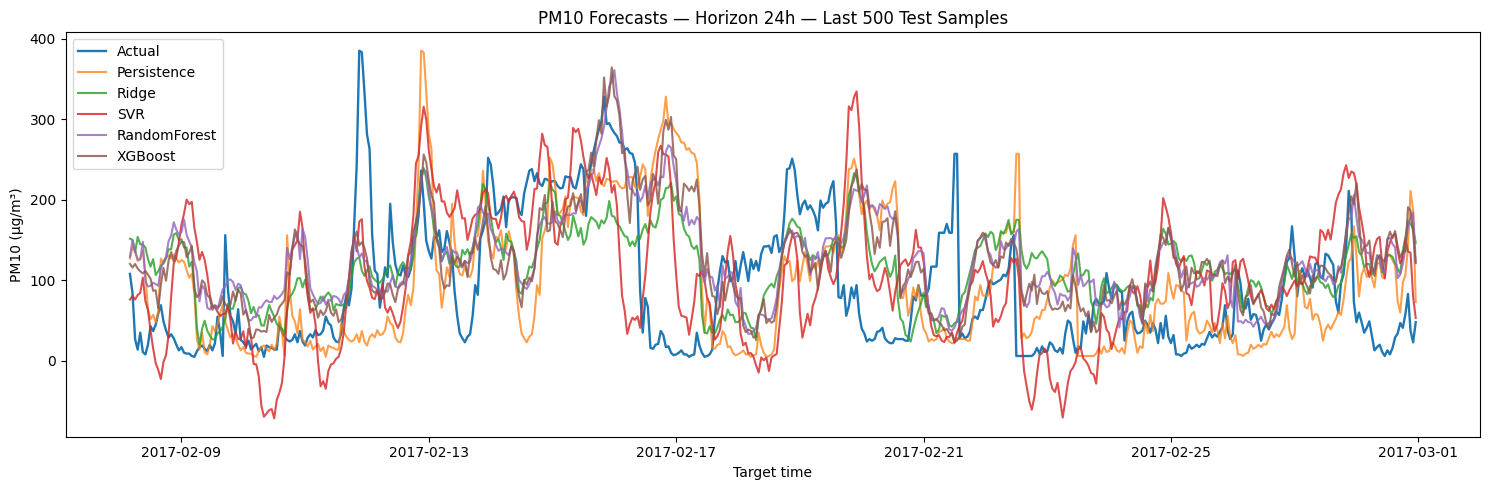

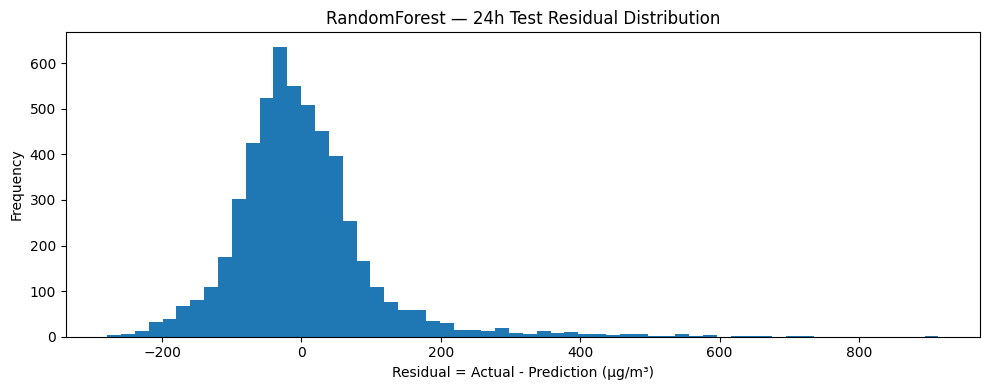

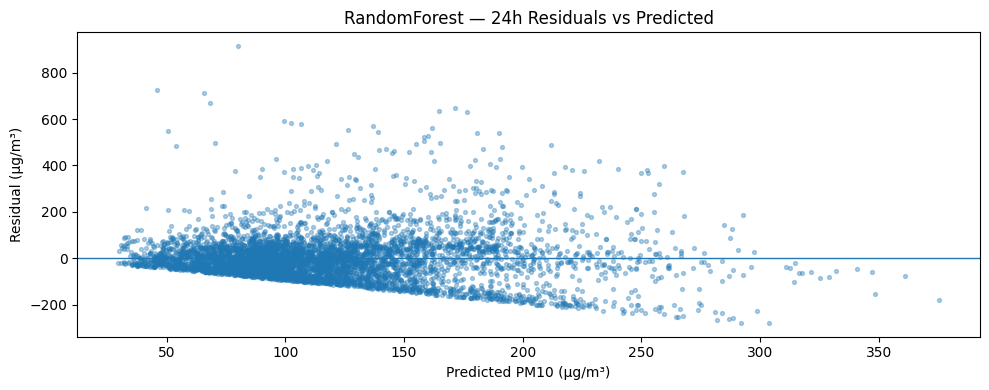

In [21]:
result_24h = run_classical_experiment(horizon=24)


# آزمایش سوم: پیش‌بینی 72 ساعت آینده

\[
(X_{t-23},\ldots,X_t)\rightarrow PM10_{t+72}
\]

باز هم فقط افق پیش‌بینی تغییر کرده است.


FORECAST HORIZON = 72 HOURS

Training Ridge for 72h horizon ...
Ridge: MAE=77.252 | RMSE=108.035 | R2=0.0357 | sMAPE=69.795% | time=0.2s

Training SVR for 72h horizon ...
SVR: MAE=97.239 | RMSE=133.024 | R2=-0.4619 | sMAPE=82.644% | time=181.1s

Training RandomForest for 72h horizon ...
RandomForest: MAE=77.940 | RMSE=108.555 | R2=0.0264 | sMAPE=70.264% | time=1321.1s

Training XGBoost for 72h horizon ...
XGBoost: MAE=78.428 | RMSE=110.009 | R2=0.0002 | sMAPE=70.570% | time=33.8s

TEST RESULTS


,Horizon_hours,Model,MAE,RMSE,R2,sMAPE_percent,Training_seconds
0,72,Ridge,77.252,108.035,0.0357,69.795,0.2
1,72,RandomForest,77.940,108.555,0.0264,70.264,1321.1
2,72,XGBoost,78.428,110.009,0.0002,70.570,33.8
3,72,SVR,97.239,133.024,-0.4619,82.644,181.1
4,72,Persistence,102.644,141.957,-0.6649,88.940,0.0



PEAK-POLLUTION RESULTS (top 10% of actual test PM10)


,Horizon_hours,Model,Peak_threshold_PM10,Peak_samples,MAE,RMSE,R2,sMAPE_percent
0,72,RandomForest,246.0,535,222.621,259.516,-3.271,85.087
1,72,Ridge,246.0,535,223.539,260.911,-3.317,84.735
2,72,XGBoost,246.0,535,223.901,262.333,-3.364,86.369
3,72,Persistence,246.0,535,230.329,264.343,-3.431,101.694
4,72,SVR,246.0,535,222.894,276.277,-3.840,88.782



Best classical model by Test RMSE: Ridge


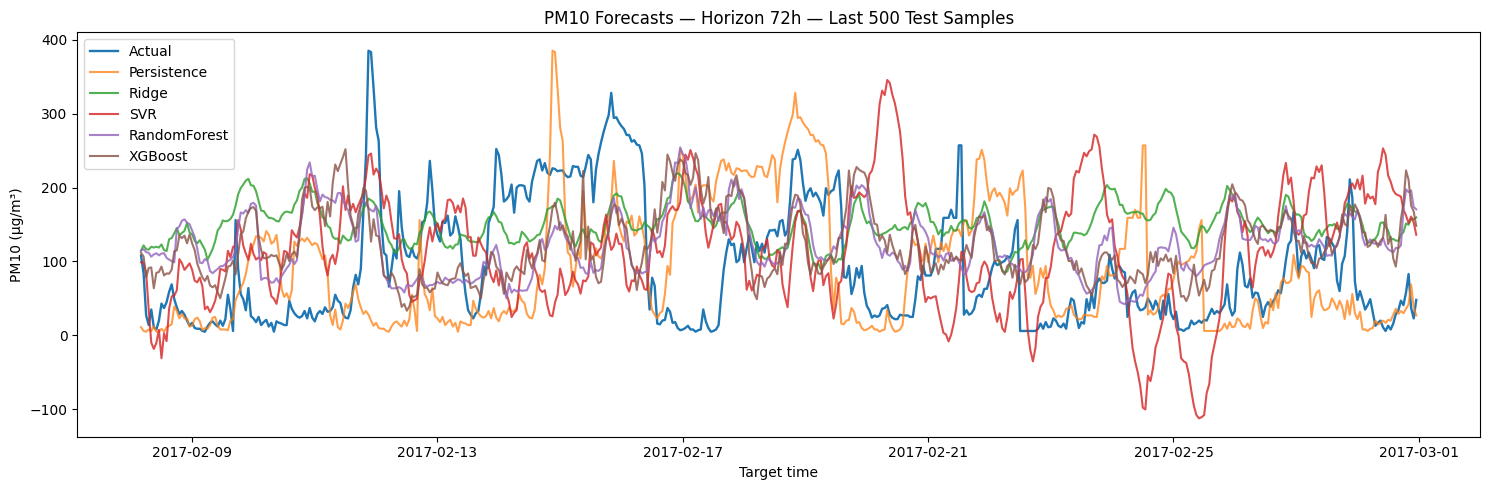

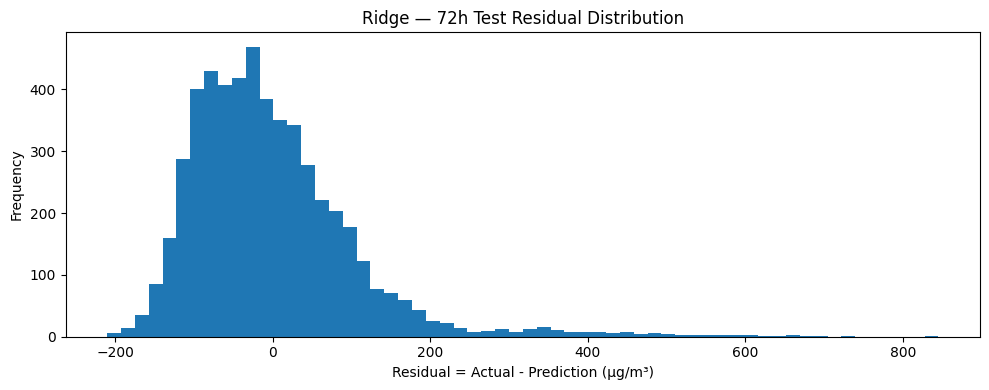

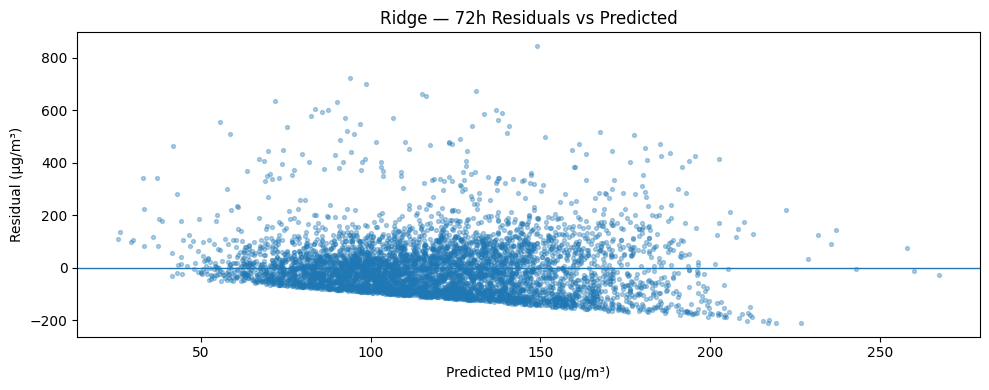

In [22]:
result_72h = run_classical_experiment(horizon=72)


# 16. مقایسه نهایی سه افق برای مدل‌های کلاسیک

این بخش همه خروجی‌ها را در یک جدول واحد جمع می‌کند.


In [23]:
all_metrics = pd.concat(
    [
        all_experiments[h]["comparison"]
        for h in HORIZONS
    ],
    ignore_index=True
)

all_metrics = all_metrics.sort_values(
    ["Horizon_hours", "RMSE"]
).reset_index(drop=True)

display(all_metrics.round({
    "MAE": 3,
    "RMSE": 3,
    "R2": 4,
    "sMAPE_percent": 3,
    "Training_seconds": 1
}))

all_metrics.to_csv(
    OUTPUT_DIR / "classical_all_horizons_test_metrics.csv",
    index=False
)

,Horizon_hours,Model,MAE,RMSE,R2,sMAPE_percent,Training_seconds
0,1,Ridge,21.355,34.571,0.9013,33.604,0.2
1,1,Persistence,20.444,35.457,0.8961,24.241,0.0
2,1,RandomForest,22.283,36.819,0.8880,27.573,1771.5
3,1,XGBoost,22.695,38.148,0.8798,27.678,35.0
4,1,SVR,32.732,54.879,0.7512,41.364,226.0
5,24,RandomForest,68.777,100.326,0.1684,63.699,1393.1
6,24,Ridge,70.083,101.371,0.1510,68.828,0.2
7,24,XGBoost,68.639,101.788,0.1440,64.336,35.2
8,24,SVR,79.909,120.884,-0.2073,77.645,197.3
9,24,Persistence,83.233,121.450,-0.2186,76.683,0.0


## 17. جدول بهترین مدل کلاسیک در هر افق

In [24]:
best_by_horizon = (
    all_metrics[all_metrics["Model"] != "Persistence"]
    .sort_values(["Horizon_hours", "RMSE"])
    .groupby("Horizon_hours", as_index=False)
    .first()
)

display(best_by_horizon.round({
    "MAE": 3,
    "RMSE": 3,
    "R2": 4,
    "sMAPE_percent": 3,
    "Training_seconds": 1
}))

,Horizon_hours,Model,MAE,RMSE,R2,sMAPE_percent,Training_seconds
0,1,Ridge,21.355,34.571,0.9013,33.604,0.2
1,24,RandomForest,68.777,100.326,0.1684,63.699,1393.1
2,72,Ridge,77.252,108.035,0.0357,69.795,0.2


## 18. مقایسه RMSE مدل‌ها در سه افق

Model,Persistence,RandomForest,Ridge,SVR,XGBoost
Horizon_hours,,,,,
1,35.457,36.819,34.571,54.879,38.148
24,121.450,100.326,101.371,120.884,101.788
72,141.957,108.555,108.035,133.024,110.009


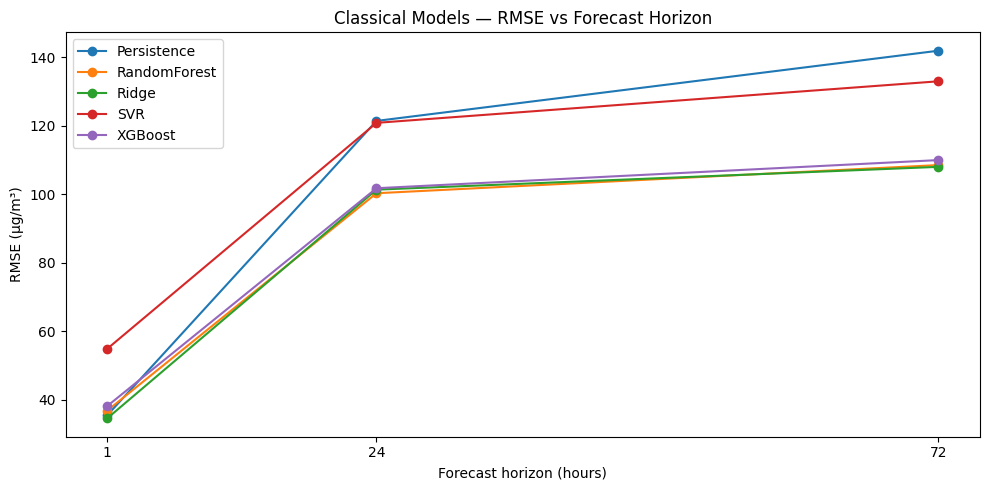

In [25]:
rmse_pivot = all_metrics.pivot(
    index="Horizon_hours",
    columns="Model",
    values="RMSE"
).sort_index()

display(rmse_pivot.round(3))

plt.figure(figsize=(10, 5))
for model_name in rmse_pivot.columns:
    plt.plot(
        rmse_pivot.index,
        rmse_pivot[model_name],
        marker="o",
        label=model_name
    )

plt.xlabel("Forecast horizon (hours)")
plt.ylabel("RMSE (µg/m³)")
plt.title("Classical Models — RMSE vs Forecast Horizon")
plt.xticks(HORIZONS)
plt.legend()
plt.tight_layout()
plt.show()

## 19. مقایسه MAE مدل‌ها در سه افق

Model,Persistence,RandomForest,Ridge,SVR,XGBoost
Horizon_hours,,,,,
1,20.444,22.283,21.355,32.732,22.695
24,83.233,68.777,70.083,79.909,68.639
72,102.644,77.940,77.252,97.239,78.428


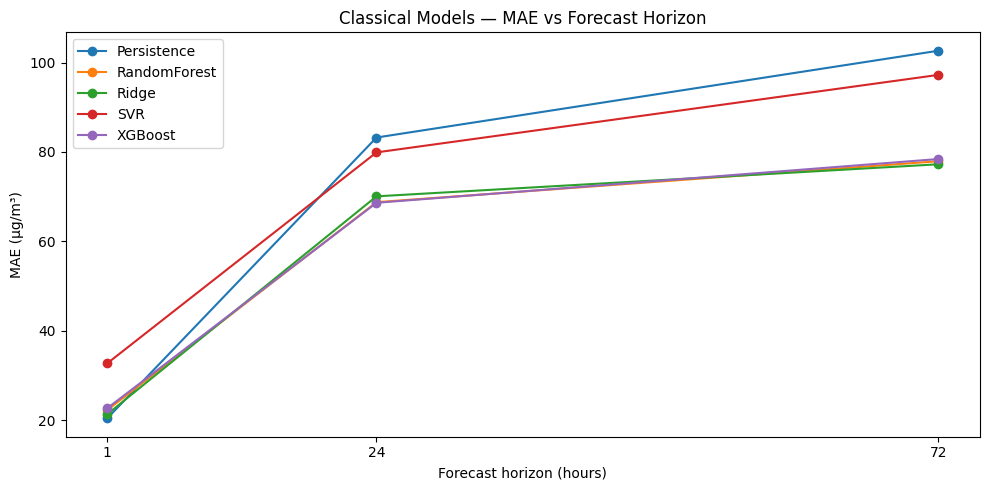

In [26]:
mae_pivot = all_metrics.pivot(
    index="Horizon_hours",
    columns="Model",
    values="MAE"
).sort_index()

display(mae_pivot.round(3))

plt.figure(figsize=(10, 5))
for model_name in mae_pivot.columns:
    plt.plot(
        mae_pivot.index,
        mae_pivot[model_name],
        marker="o",
        label=model_name
    )

plt.xlabel("Forecast horizon (hours)")
plt.ylabel("MAE (µg/m³)")
plt.title("Classical Models — MAE vs Forecast Horizon")
plt.xticks(HORIZONS)
plt.legend()
plt.tight_layout()
plt.show()


## 20. جدول Peak Pollution در تمام افق‌ها


In [27]:
all_peak_metrics = pd.concat(
    [
        all_experiments[h]["peak_comparison"]
        for h in HORIZONS
    ],
    ignore_index=True
)

all_peak_metrics = all_peak_metrics.sort_values(
    ["Horizon_hours", "RMSE"]
).reset_index(drop=True)

display(all_peak_metrics.round(3))

all_peak_metrics.to_csv(
    OUTPUT_DIR / "classical_all_horizons_peak_metrics.csv",
    index=False
)

,Horizon_hours,Model,Peak_threshold_PM10,Peak_samples,MAE,RMSE,R2,sMAPE_percent
0,1,Persistence,246.0,535,40.606,65.383,0.729,12.188
1,1,Ridge,246.0,535,43.087,66.236,0.722,13.005
2,1,RandomForest,246.0,535,45.253,69.306,0.695,13.325
3,1,XGBoost,246.0,535,51.767,78.783,0.606,15.126
4,1,SVR,246.0,535,95.156,137.788,-0.204,28.461
5,24,Persistence,246.0,535,172.336,216.345,-1.968,63.262
6,24,RandomForest,246.0,535,194.011,236.293,-2.540,69.944
7,24,XGBoost,246.0,535,198.707,241.954,-2.712,73.976
8,24,Ridge,246.0,535,207.282,243.284,-2.753,77.892
9,24,SVR,246.0,535,213.048,279.609,-3.957,83.268



# 21. ذخیره Scalerها و پیکربندی کامل آزمایش

این فایل‌ها برای بازتولید نتایج و مقایسه بعدی با RNN/LSTM/GRU ذخیره می‌شوند.


In [28]:
joblib.dump(
    feature_scaler,
    OUTPUT_DIR / "feature_scaler.joblib"
)
joblib.dump(
    target_scaler,
    OUTPUT_DIR / "target_scaler.joblib"
)

config = {
    "target": TARGET,
    "features": FEATURES,
    "number_of_features": len(FEATURES),
    "lookback_hours": LOOKBACK,
    "horizons_hours": HORIZONS,
    "flattened_input_dimension": LOOKBACK * len(FEATURES),
    "train_ratio": TRAIN_RATIO,
    "validation_ratio": VAL_RATIO,
    "test_ratio": TEST_RATIO,
    "seed": SEED,
    "models": CLASSICAL_MODEL_CONFIG,
    "fair_comparison_note": (
        "Same Gucheng dataset, 19 features, chronological split, "
        "causal missing-value handling, train-only scaling, lookback=24, "
        "Persistence baseline and evaluation metrics as the RNN/LSTM/GRU experiments. "
        "Only the representation is flattened to 456 features because classical "
        "estimators require a 2D design matrix."
    )
}

with open(
    OUTPUT_DIR / "experiment_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("Saved all artifacts to:", OUTPUT_DIR.resolve())

Saved all artifacts to: /content/outputs_gucheng_classical_all_horizons



# 22. کنترل نهایی عدالت مقایسه با مدل‌های عمیق

برای مقایسه نهایی Classical ML و Deep Learning باید موارد زیر ثابت بمانند:

| مؤلفه | Classical ML | RNN/LSTM/GRU |
|---|---|---|
| Dataset | Gucheng | Gucheng |
| Target | PM10 | PM10 |
| Features | 19 | 19 |
| Look-back | 24 h | 24 h |
| Horizons | 1 / 24 / 72 h | 1 / 24 / 72 h |
| Train/Val/Test | 70/15/15 chronological | 70/15/15 chronological |
| Missing values | causal forward fill + Train statistics | همان |
| Scaling | fit on Train only | همان |
| Baseline | Persistence | Persistence |
| Metrics | MAE/RMSE/R²/sMAPE | همان |
| Peak evaluation | Test 90th percentile | همان |
| Test set | untouched | untouched |

تنها تفاوت الزامی:

- Deep Learning: `(samples, 24, 19)`
- Classical ML: `(samples, 456)`

این تبدیل فقط تغییر شکل است و **هیچ اطلاعاتی حذف یا اضافه نمی‌کند**.

## نکته برای مرحله بعد

اگر قرار باشد Hyperparameter Tuning انجام شود، برای حفظ عدالت نباید فقط یک مدل مانند XGBoost بهینه شود. باید بودجه‌ی tuning و داده‌ی Validation برای تمام مدل‌هایی که قرار است به‌صورت نهایی مقایسه شوند، به‌صورت از پیش تعریف‌شده و منصفانه در نظر گرفته شود.
